In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, root_mean_squared_error, mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

# Полиномиальная Регрессия
$$
y = 0.5x^3 - 3x^2 + 2x + noise
$$

In [5]:
n = 120
X = np.linspace(-4, 6, n).reshape(-1, 1)
noise = np.random.normal(0, 6, n)

In [6]:
y = 0.5*X.flatten()**3 - 3*X.flatten()**2 + 2*X.flatten() + noise

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)
len(X_train), len(X_test)

(90, 30)

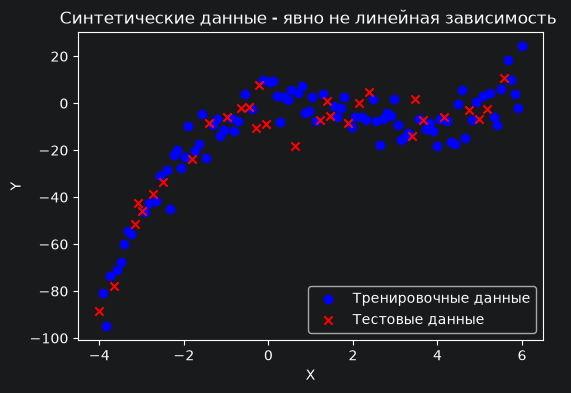

In [10]:
plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, color='blue', label='Тренировочные данные')
plt.scatter(X_test, y_test, color='red', label='Тестовые данные', marker='x')
plt.title('Синтетические данные - явно не линейная зависимость ')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

In [13]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_train_linear = linear_model.predict(X_train)
y_pred_test_linear = linear_model.predict(X_test)

r2_train_linear = r2_score(y_train, y_pred_train_linear)
r2_test_linear = r2_score(y_test, y_pred_test_linear)

rmse_train_linear = root_mean_squared_error(y_train, y_pred_train_linear)
rmse_test_linear = root_mean_squared_error(y_test, y_pred_test_linear)

print(f"""
Linear Regression Model:
    Train RMSE: {rmse_train_linear: .2f}, Test RMSE: {rmse_test_linear:.2f}
    Train R2 Score: {r2_train_linear:.2f}, Test R2 Score: {r2_test_linear:.2f}
""")


Linear Regression Model:
    Train RMSE:  16.40, Test RMSE: 16.41
    Train R2 Score: 0.44, Test R2 Score: 0.52



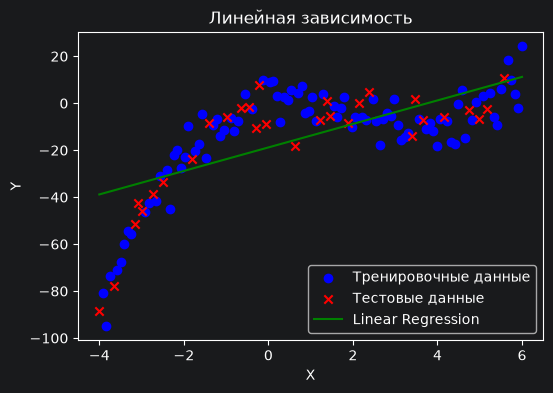

In [14]:
X_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_grid_linear = linear_model.predict(X_grid)

plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, color='blue', label='Тренировочные данные')
plt.scatter(X_test, y_test, color='red', label='Тестовые данные', marker='x')
plt.plot(X_grid, y_grid_linear, color='green', label='Linear Regression')
plt.title('Линейная зависимость')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

In [16]:
poly_pipe = Pipeline([
    ('poly', PolynomialFeatures(include_bias=False)),
    ('linear', LinearRegression())
])

param_grid = {
    'poly__degree': list(range(1, 11)),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=poly_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid.fit(X_train, y_train)
best_degree = grid.best_params_['poly__degree']
best_cv_rmse = -grid.best_score_
print(f"""
Polynomial Regression Model Best Degree: {best_degree}
Best CV RMSE: {best_cv_rmse:.2f}
""")


Polynomial Regression Model Best Degree: 3
Best CV RMSE: 6.54



In [17]:
rows = []

for d in range(1, 11):
    pipe = Pipeline([
        ('poly', PolynomialFeatures(include_bias=False, degree=d)),
        ('linear', LinearRegression())
    ])

    pipe.fit(X_train, y_train)
    y_tr = pipe.predict(X_train)
    y_tst = pipe.predict(X_test)

    rows.append(
        {
            'degree': d,
            'train_rmse': root_mean_squared_error(y_train, y_tr),
            'test_rmse': root_mean_squared_error(y_test, y_tst),
            'train_r2': r2_score(y_train, y_tr),
            'test_r2': r2_score(y_test, y_tst),
        }
    )

metrics_df = pd.DataFrame(rows).set_index("degree")
metrics_df

,train_rmse,test_rmse,train_r2,test_r2
degree,,,,
1,16.401737,16.410504,0.441724,0.522481
2,12.132015,10.287058,0.694554,0.812358
3,6.277486,6.279753,0.918221,0.930075
4,6.184492,6.523597,0.920626,0.924539
5,6.182951,6.564472,0.920666,0.923591
6,6.139680,6.653457,0.921772,0.921505
7,6.116233,6.718959,0.922369,0.919952
8,6.199642,6.683838,0.920237,0.920787
9,6.429720,6.816304,0.914207,0.917616


In [18]:
best_model = Pipeline([
        ('poly', PolynomialFeatures(include_bias=False, degree=best_degree)),
        ('linear', LinearRegression())
    ])

best_model.fit(X_train, y_train)
y_best_train = best_model.predict(X_train)
y_best_test = best_model.predict(X_test)

print(f"""
Polynomial Regression Model:
    Best Degree: {best_degree}
    Best Train RMSE: {root_mean_squared_error(y_train, y_best_train):.2f}
    Best Test RMSE: {root_mean_squared_error(y_test, y_best_test):.2f}
    Best Train R2 Score: {r2_score(y_train, y_best_train):.2f}
    Best Test R2 Score: {r2_score(y_test, y_best_test):.2f}
""")


Polynomial Regression Model:
    Best Degree: 3
    Best Train RMSE: 6.28
    Best Test RMSE: 6.28
    Best Train R2 Score: 0.92
    Best Test R2 Score: 0.93    



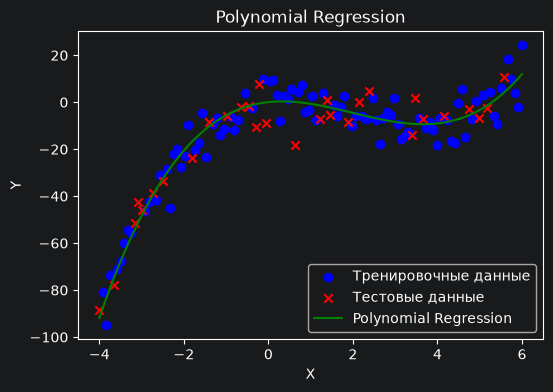

In [19]:
X_dense = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_dense_best = best_model.predict(X_grid)

plt.figure(figsize=(6, 4))
plt.scatter(X_train, y_train, color='blue', label='Тренировочные данные')
plt.scatter(X_test, y_test, color='red', label='Тестовые данные', marker='x')
plt.plot(X_dense, y_dense_best, color='green', label='Polynomial Regression')
plt.title('Polynomial Regression')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

In [21]:
def fit_metrics_for_degree(d):
    pipe = Pipeline([
    ("poly", PolynomialFeatures(degree=d,include_bias=False)),
    ("lin", LinearRegression())
])
    pipe.fit(X_train, y_train)
    ytr = pipe.predict(X_train)
    yte = pipe.predict(X_test)
    return  pipe, {
        "degree": d,
        "train_R2": r2_score(y_train, ytr),
        "test_R2": r2_score(y_test, yte),
        "train_rmse": root_mean_squared_error(y_train, ytr),
        "test_rmse": root_mean_squared_error(y_test, yte),
    }

model_low, m_low = fit_metrics_for_degree(1)
model_best, m_best = best_model, {
    "degree": best_degree,
    "train_R2": r2_score(y_train, best_model.predict(X_train)),
        "test_R2": r2_score(y_test, best_model.predict(X_test)),
        "train_rmse": root_mean_squared_error(y_train, best_model.predict(X_train)),
        "test_rmse": root_mean_squared_error(y_test, best_model.predict(X_test)),
}

model_high, m_high = fit_metrics_for_degree(11)
pd.DataFrame([m_low, m_best, m_high])

,degree,train_R2,test_R2,train_rmse,test_rmse
0,1,0.441724,0.522481,16.401737,16.410504
1,3,0.918221,0.930075,6.277486,6.279753
2,11,0.842658,0.884761,8.707384,8.061707


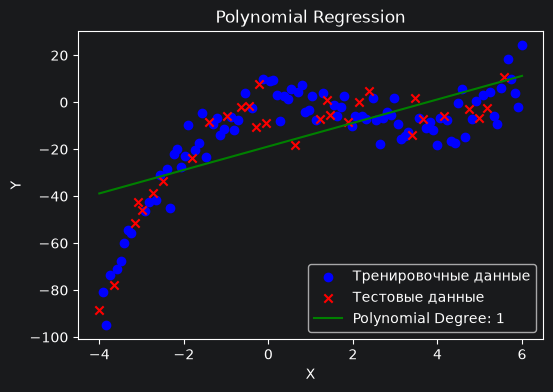

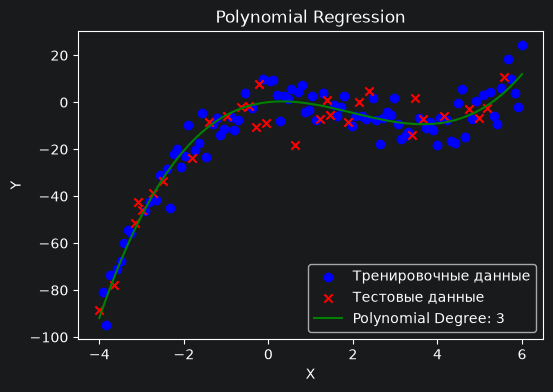

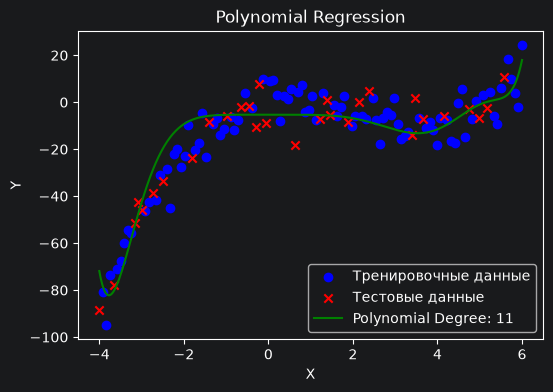

In [22]:
for d, model in [(1, model_low), [best_degree, model_best], (11, model_high)]:
    plt.figure(figsize=(6, 4))
    y_curve = model.predict(X_dense)
    plt.scatter(X_train, y_train, color='blue', label='Тренировочные данные')
    plt.scatter(X_test, y_test, color='red', label='Тестовые данные', marker='x')
    plt.plot(X_dense, y_curve, color='green', label=f'Polynomial Degree: {d}')
    plt.title('Polynomial Regression')
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.legend()
    plt.show()